# Analisis Pengaruh Kegiatan Internal dan Eksternal terhadap Performa Akademik Mahasiswa

**UTS Data Science 2026/2027**· Program Studi Informatika, UPN "Veteran" Yogyakarta · Dosen pengampu: Dhimas Arief Dharmawan, S.T., Ph.D.

Anggota kelompok:  
Aji Gersome Diliadi (123240043)  
Muhammad Restu Firmansyah (123240050)  
Yusyfi Akira Arlyn Alzena (123240061)  
Hendri Prasetyo (123240066) 


Notebook ini mengikuti kerangka **CRISP-DM** dan mencakup lima bagian untuk UTS:

| Bagian | Isi |
|---|---|
| 1 | Business Understanding |
| 2 | Data Gathering |
| 3 | EDA (data mentah) |
| 4 | Cleaning |
| 5 | EDA lanjutan pada data bersih (hubungan kegiatan dengan CGPA) |
| 6 | Preprocessing |

Setiap bagian diawali penjelasan singkat, lalu kode, lalu catatan hasilnya. Angka dan gambar di sini sama dengan yang ada di laporan.

## IMPORT LIBRARY

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

os.makedirs('fig', exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

---
# 2. Data Gathering

**Sumber.** Rahman, A. T., Lamia, S., Shishir, A. H., & Barsa, M. M. (2024). *Students_Academic_Performance_Evaluation_Dataset* (Versi 1). Mendeley Data. https://doi.org/10.17632/dc3797vf3t.1

**Cara memperoleh:** Unduh file `Students_Performance_data_set.xlsx` dari tautan DOI di atas. Salinannya sudah ada di folder `data/` repository ini.

**Lisensi:** CC BY 4.0: data boleh dipakai dan diolah asalkan sumbernya disebut.

**Isi:** Hasil survei online mahasiswa *Computer Science and Engineering* di sebuah universitas swasta di Bangladesh. Satu baris = satu mahasiswa. Nama kolom aslinya berupa kalimat pertanyaan, jadi diganti dengan nama pendek.

## MEMUAT DATASET

In [2]:
df = pd.read_csv('data/Students_Performance_data_set.csv')
print('Jumlah baris dan kolom:', df.shape)

df.columns = ['admit_year','gender','age','hsc_year','program','semester','scholarship','uni_transport',
              'study_hours','study_sessions','learning_mode','smartphone','pc','social_media_hours','english',
              'attendance','probation','suspension','consultancy','skills','skill_hours','interest','relationship',
              'cocurricular','living_with','health_issue','prev_sgpa','disability','cgpa','credits','income']
df.head()

Jumlah baris dan kolom: (1194, 31)


,admit_year,gender,age,hsc_year,program,semester,scholarship,uni_transport,study_hours,study_sessions,learning_mode,smartphone,pc,social_media_hours,english,attendance,probation,suspension,consultancy,skills,skill_hours,interest,relationship,cocurricular,living_with,health_issue,prev_sgpa,disability,cgpa,credits,income
0,2018,Male,24,2016,BCSE,12,Yes,No,3,2,Offline,Yes,Yes,5,Intermediate,90,No,No,Yes,Software Development,2,Data Schince,Single,Yes,Bachelor,No,2.68,No,3.15,75,25000
1,2021,Male,22,2020,BCSE,4,Yes,Yes,3,2,Online,Yes,Yes,3,Basic,96,Yes,No,No,Web development,2,Event management,Single,Yes,Family,No,2.68,No,3.15,36,100000
2,2020,Female,21,2019,BCSE,5,No,No,3,3,Offline,Yes,Yes,3,Intermediate,80,No,No,Yes,Programming,1,Software,Single,No,Bachelor,No,2.68,No,3.15,50,50000
3,2021,Male,20,2020,BCSE,4,Yes,No,1,3,Offline,Yes,Yes,2,Intermediate,88,No,No,Yes,Programming,1,Artificial Intelligence,Single,No,Bachelor,Yes,2.68,No,3.15,36,62488
4,2021,Male,22,2019,BCSE,4,Yes,No,3,1,Online,Yes,Yes,2,Intermediate,80,No,No,Yes,Programming,1,Software,Relationship,No,Bachelor,Yes,2.68,No,3.15,36,50000


In [3]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1194 entries, 0 to 1193
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   admit_year          1194 non-null   int64  
 1   gender              1194 non-null   object 
 2   age                 1194 non-null   int64  
 3   hsc_year            1194 non-null   int64  
 4   program             1194 non-null   object 
 5   semester            1194 non-null   int64  
 6   scholarship         1194 non-null   object 
 7   uni_transport       1194 non-null   object 
 8   study_hours         1194 non-null   int64  
 9   study_sessions      1194 non-null   int64  
 10  learning_mode       1194 non-null   object 
 11  smartphone          1194 non-null   object 
 12  pc                  1194 non-null   object 
 13  social_media_hours  1194 non-null   int64  
 14  english             1194 non-null   object 
 15  attendance          1194 non-null   object 
 16  probat

In [4]:
# Melihat statistik deskriptif dataset
df.describe()

,admit_year,age,hsc_year,semester,study_hours,study_sessions,social_media_hours,skill_hours,prev_sgpa,cgpa,credits,income
count,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1194.000000,1.194000e+03
mean,2020.515075,21.343384,2019.214405,6.539363,3.131491,1.940536,3.289782,2.185092,2.683945,3.165603,71.842546,6.248812e+04
std,1.354954,1.613338,1.380960,3.809884,1.649597,0.856305,2.289547,1.296101,0.871592,0.750132,48.074338,7.617356e+04
min,2013.000000,18.000000,2012.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000e+03
25%,2020.000000,20.000000,2019.000000,3.000000,2.000000,1.000000,2.000000,1.000000,2.200000,2.900000,23.000000,3.000000e+04
50%,2021.000000,21.000000,2020.000000,7.000000,3.000000,2.000000,3.000000,2.000000,2.680000,3.210000,78.000000,5.000000e+04
75%,2022.000000,22.000000,2020.000000,10.000000,4.000000,2.000000,4.000000,3.000000,3.380000,3.670000,117.000000,7.400000e+04
max,2023.000000,27.000000,2028.000000,24.000000,13.000000,7.000000,20.000000,12.000000,4.000000,4.000000,145.000000,2.000000e+06


**Data dictionary ringkas dan peran variabel.** Variabel dikelompokkan menurut perannya dalam proyek. Penjelasan lengkap 31 variabel ada di laporan (Tabel 5).

In [5]:
peran = {
    'Target': ['cgpa'],
    'Internal': ['attendance', 'consultancy', 'cocurricular'],
    'Eksternal': ['study_hours', 'study_sessions', 'social_media_hours', 'skill_hours', 'skills'],
    'Kontrol': ['prev_sgpa', 'semester', 'credits', 'english'],
}
peran['Latar'] = [c for c in df.columns if c not in sum(peran.values(), [])]
for k, v in peran.items():
    print(f'{k:10s} ({len(v)}): {", ".join(v)}')

Target     (1): cgpa
Internal   (3): attendance, consultancy, cocurricular
Eksternal  (5): study_hours, study_sessions, social_media_hours, skill_hours, skills
Kontrol    (4): prev_sgpa, semester, credits, english
Latar      (18): admit_year, gender, age, hsc_year, program, scholarship, uni_transport, learning_mode, smartphone, pc, probation, suspension, interest, relationship, living_with, health_issue, disability, income


---
# 3. EDA (data mentah)

Tahap ini memeriksa data apa adanya untuk menemukan masalah yang perlu dibersihkan di bagian 4: nilai kosong, duplikat, tipe data, label tidak seragam, nilai tidak wajar, dan outlier.

## 3.1 Nilai kosong, duplikat, dan tipe data

In [6]:
kosong = df.isna().sum()
print('Kolom dengan nilai kosong:'); print(kosong[kosong > 0])
print('\nBaris duplikat:', df.duplicated().sum())
print('\nTipe kolom kehadiran:', df.attendance.dtype, '(seharusnya angka)')
print('\nIsian kehadiran yang bukan angka:',
      df.attendance[pd.to_numeric(df.attendance, errors='coerce').isna()].tolist())

Kolom dengan nilai kosong:
skills    1
dtype: int64

Baris duplikat: 0

Tipe kolom kehadiran: object (seharusnya angka)

Isian kehadiran yang bukan angka: ['94-98']


**Catatan.** Hanya kolom `skills` yang punya nilai kosong (1 baris, 0,08%). Tidak ada baris ganda. Kolom kehadiran terbaca sebagai teks karena ada satu isian `94-98`.

## 3.2 Label kategori

In [7]:
for c in ['health_issue', 'relationship', 'english']:
    print(df[c].value_counts(), '\n')
print(df.skills.value_counts().head(12), '\n')
print(df.interest.value_counts().head(15))

health_issue
No     983
Yes    207
no       3
N        1
Name: count, dtype: int64 

relationship
Single               896
Relationship         186
Married               96
Engaged               15
In a relationship      1
Name: count, dtype: int64 

english
Intermediate    670
Basic           304
Advance         220
Name: count, dtype: int64 

skills
Programming                533
Web development            251
Networking                 153
Cyber security              87
Artificial Intelligence     51
Machine Learning            37
Software Development        23
Nothing                      4
No skills                    3
No skill                     2
Haven't started yet          2
Web development skill        2
Name: count, dtype: int64 

interest
Software                   648
Hardware                   165
Data Science               132
UI/UX                       84
NETWORKING                  58
Machine Learning            56
Artificial Intelligence     29
Web development     

**Catatan.** Label tidak seragam: `health_issue` berisi `no` dan `N` selain Yes/No; `relationship` punya `In a relationship` (1 baris) di samping `Relationship`; `skills` memakai beberapa tulisan untuk arti yang sama (`Nothing`, `No skills`, `No skill`, `No Skill`); `interest` bercampur huruf besar dan kecil serta salah ketik `Data Schince`.

## 3.3 Statistik dan nilai tidak wajar

In [8]:
num_cols = ['age', 'hsc_year', 'semester', 'study_hours', 'study_sessions', 'social_media_hours',
            'skill_hours', 'prev_sgpa', 'cgpa', 'credits', 'income']
print(df[num_cols].describe().T.round(2))

nol = df[df.cgpa == 0]
print('\nCGPA = 0:', len(nol), '| semester 1:', (nol.semester == 1).sum(),
      '| kredit 0:', (nol.credits == 0).sum(), '| angkatan:', nol.admit_year.unique())
print('Tahun lulus HSC > 2024:', (df.hsc_year > 2024).sum(), '| semester > 14:', (df.semester > 14).sum())
print('Media sosial > 12 jam:', (df.social_media_hours > 12).sum(),
      '| keterampilan > 8 jam:', (df.skill_hours > 8).sum(),
      '| pendapatan > 500.000:', (df.income > 500000).sum())

                     count      mean       std     min      25%       50%       75%        max
age                 1194.0     21.34      1.61    18.0     20.0     21.00     22.00       27.0
hsc_year            1194.0   2019.21      1.38  2012.0   2019.0   2020.00   2020.00     2028.0
semester            1194.0      6.54      3.81     1.0      3.0      7.00     10.00       24.0
study_hours         1194.0      3.13      1.65     0.0      2.0      3.00      4.00       13.0
study_sessions      1194.0      1.94      0.86     0.0      1.0      2.00      2.00        7.0
social_media_hours  1194.0      3.29      2.29     0.0      2.0      3.00      4.00       20.0
skill_hours         1194.0      2.19      1.30     0.0      1.0      2.00      3.00       12.0
prev_sgpa           1194.0      2.68      0.87     0.0      2.2      2.68      3.38        4.0
cgpa                1194.0      3.17      0.75     0.0      2.9      3.21      3.67        4.0
credits             1194.0     71.84     48.07    

**Catatan:** 39 mahasiswa angkatan 2022 ber-CGPA 0, hampir semuanya di semester 1 dan belum punya kredit: ini menandakan mahasiswa baru yang belum punya nilai, bukan CGPA yang sungguh nol. Ada juga tahun lulus HSC 2028 (salah input), semester sampai 24, dan beberapa nilai ekstrem pada jam media sosial dan pendapatan.

## 3.4 Outlier (metode IQR) dan distribusi CGPA mentah

Outlier IQR pada data mentah:
{'cgpa': 45, 'att': 36, 'study_hours': 22, 'social_media_hours': 71, 'skill_hours': 8, 'income': 61}


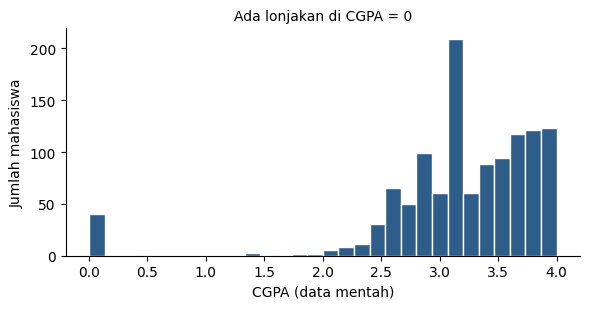

In [9]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

mentah = df.assign(att=pd.to_numeric(df.attendance, errors='coerce'))
print('Outlier IQR pada data mentah:')
print({c: iqr_outliers(mentah[c]) for c in ['cgpa', 'att', 'study_hours', 'social_media_hours', 'skill_hours', 'income']})

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(df.cgpa, bins=30, color='#2F5D8A', edgecolor='white')
ax.set_xlabel('CGPA (data mentah)'); ax.set_ylabel('Jumlah mahasiswa')
ax.set_title('Ada lonjakan di CGPA = 0', fontsize=10)
plt.tight_layout(); plt.show()

**Catatan:** CGPA punya 45 outlier pada data mentah, hampir semuanya adalah 39 mahasiswa ber-CGPA 0. Outlier pada variabel lain cukup banyak tetapi sebagian besar masih masuk akal (misalnya jam media sosial tinggi), jadi tidak dibuang otomatis.

---
# 4. Cleaning

Aturan yang dipakai:
1. Label yang artinya sama disatukan.
2. Isian yang tidak bisa dibaca sebagai angka dijadikan kosong, bukan ditebak.
3. Nilai yang mustahil ditandai kosong.
4. Mahasiswa yang belum punya CGPA dikeluarkan dari analisis.
5. Outlier yang masuk akal **dipertahankan**. Analisis memakai uji yang tahan outlier (Spearman, Mann-Whitney).

In [10]:
bersih = df.copy()

# 1. Samakan label
bersih['health_issue'] = bersih.health_issue.replace({'no': 'No', 'N': 'No'})
bersih['relationship'] = bersih.relationship.replace({'In a relationship': 'Relationship'})
bersih['skills'] = (bersih.skills.fillna('Unknown').str.strip().str.lower()
                    .replace({'nothing': 'no skill', 'no skills': 'no skill'}))
bersih['interest'] = bersih.interest.str.strip().str.lower().replace({'data schince': 'data science'})

# 2. Kehadiran jadi angka; isian '94-98' dianggap kosong (hanya 1 baris)
bersih['att'] = pd.to_numeric(bersih.attendance, errors='coerce')

# 3. Nilai mustahil jadi kosong (tahun lulus HSC 2028)
bersih.loc[bersih.hsc_year > 2024, 'hsc_year'] = np.nan

# 4. Keluarkan mahasiswa yang belum punya CGPA
sebelum = len(bersih)
bersih = bersih[bersih.cgpa > 0].copy()

print(f'Baris sebelum: {sebelum} | sesudah: {len(bersih)} | dikeluarkan: {sebelum - len(bersih)}')
print('Kehadiran kosong:', bersih.att.isna().sum(), '| HSC kosong:', bersih.hsc_year.isna().sum())
print('Label health_issue:', bersih.health_issue.unique().tolist())
print('Outlier IQR setelah cleaning:',
      {c: iqr_outliers(bersih[c]) for c in ['cgpa', 'att', 'study_hours', 'social_media_hours', 'skill_hours', 'income']})

Baris sebelum: 1194 | sesudah: 1155 | dikeluarkan: 39
Kehadiran kosong: 1 | HSC kosong: 1
Label health_issue: ['No', 'Yes']
Outlier IQR setelah cleaning: {'cgpa': 8, 'att': 36, 'study_hours': 21, 'social_media_hours': 70, 'skill_hours': 8, 'income': 58}


**Catatan.** Tersisa **1.155 mahasiswa**. Outlier CGPA turun dari 45 menjadi 8 setelah mahasiswa baru dikeluarkan. Nilai kosong yang ada (1 kehadiran, 1 tahun HSC) tidak membuat baris dihapus karena kolom lainnya masih lengkap; pengisiannya ditangani di bagian Preprocessing.

---
# 5. EDA lanjutan pada data bersih

Bagian ini menjawab pertanyaan proyek: kegiatan mana yang berhubungan dengan CGPA. Uji yang dipakai adalah korelasi Spearman (variabel angka) serta Welch t-test dan Mann-Whitney (dua kelompok), dengan α = 0,05. Angka di bagian ini yang dipakai pada Bab II laporan.

## 5.1 Gambaran CGPA

                     count   mean  median    std   min    max
cgpa                1155.0   3.27    3.25   0.48  0.13    4.0
prev_sgpa           1155.0   2.77    2.68   0.74  0.00    4.0
att                 1154.0  88.00   90.00  15.45  0.00  100.0
study_hours         1155.0   3.13    3.00   1.64  0.00   13.0
social_media_hours  1155.0   3.30    3.00   2.30  0.00   20.0
skill_hours         1155.0   2.21    2.00   1.30  0.00   12.0

Skewness CGPA: -0.84
Rata-rata CGPA menurut probation:
probation
No     3.37
Yes    3.00
Name: cgpa, dtype: float64


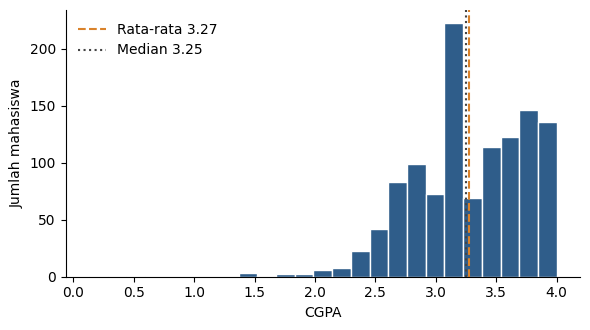

In [11]:
d = bersih
kolom = ['cgpa', 'prev_sgpa', 'att', 'study_hours', 'social_media_hours', 'skill_hours']
print(d[kolom].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T.round(2))
print('\nSkewness CGPA:', round(d.cgpa.skew(), 2))
print('Rata-rata CGPA menurut probation:'); print(d.groupby('probation').cgpa.mean().round(2))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(d.cgpa, bins=25, color='#2F5D8A', edgecolor='white')
ax.axvline(d.cgpa.mean(), color='#D9822B', ls='--', lw=1.5, label=f'Rata-rata {d.cgpa.mean():.2f}')
ax.axvline(d.cgpa.median(), color='#444', ls=':', lw=1.5, label=f'Median {d.cgpa.median():.2f}')
ax.set_xlabel('CGPA'); ax.set_ylabel('Jumlah mahasiswa'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('fig/g1_cgpa.png', dpi=200); plt.show()

**Catatan (Gambar 1):** Rata-rata CGPA 3,27 dan median 3,25. Distribusi condong ke kiri: sebagian besar mahasiswa di atas 3,0 dengan ekor kecil ke nilai rendah. Mahasiswa yang pernah *probation* rata-rata ber-CGPA 3,00, yang tidak pernah 3,37.

## 5.2 Kegiatan internal: kehadiran, ko-kurikuler, konsultasi

In [12]:
m = d.att.notna()
r, p = stats.spearmanr(d.loc[m, 'att'], d.loc[m, 'cgpa'])
print(f'Kehadiran vs CGPA: Spearman {r:.2f}, p = {p:.4f}')
print(f"CGPA kehadiran 100%: {d[d.att == 100].cgpa.mean():.2f} | kehadiran <= 75%: {d[d.att <= 75].cgpa.mean():.2f}")

for col in ['cocurricular', 'consultancy']:
    ya, tidak = d[d[col] == 'Yes'].cgpa, d[d[col] == 'No'].cgpa
    print(f'{col}: ya {ya.mean():.3f} (n={len(ya)}) vs tidak {tidak.mean():.3f} (n={len(tidak)}) | '
          f'Welch p = {stats.ttest_ind(ya, tidak, equal_var=False).pvalue:.2f} | '
          f'Mann-Whitney p = {stats.mannwhitneyu(ya, tidak).pvalue:.2f}')

Kehadiran vs CGPA: Spearman 0.25, p = 0.0000
CGPA kehadiran 100%: 3.39 | kehadiran <= 75%: 3.12
cocurricular: ya 3.275 (n=485) vs tidak 3.271 (n=670) | Welch p = 0.88 | Mann-Whitney p = 0.75
consultancy: ya 3.256 (n=632) vs tidak 3.293 (n=523) | Welch p = 0.20 | Mann-Whitney p = 0.22


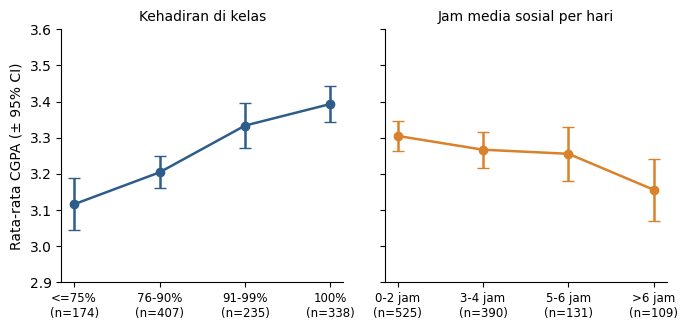

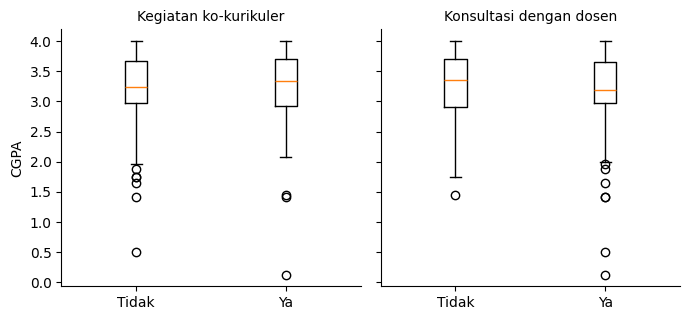

In [13]:
def ci(s): return 1.96 * s.std(ddof=1) / np.sqrt(len(s))
d = d.assign(
    attbin=pd.cut(d.att, [-1, 75, 90, 99, 100], labels=['<=75%', '76-90%', '91-99%', '100%']),
    smbin=pd.cut(d.social_media_hours, [-1, 2, 4, 6, 100], labels=['0-2 jam', '3-4 jam', '5-6 jam', '>6 jam']))

fig, axs = plt.subplots(1, 2, figsize=(7, 3.4), sharey=True)
for ax, col, t, c in [(axs[0], 'attbin', 'Kehadiran di kelas', '#2F5D8A'), (axs[1], 'smbin', 'Jam media sosial per hari', '#D9822B')]:
    g = d.groupby(col, observed=True).cgpa
    ax.errorbar(range(len(g.mean())), g.mean(), yerr=g.apply(ci), fmt='o-', color=c, capsize=4, lw=1.8)
    ax.set_xticks(range(len(g.mean()))); ax.set_xticklabels([f'{k}\n(n={n})' for k, n in g.size().items()], fontsize=8.5)
    ax.set_title(t, fontsize=10); ax.set_ylim(2.9, 3.6)
axs[0].set_ylabel('Rata-rata CGPA (± 95% CI)')
plt.tight_layout(); plt.savefig('fig/g2_hadir_sosmed.png', dpi=200); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(7, 3.3), sharey=True)
for ax, col, t in [(axs[0], 'cocurricular', 'Kegiatan ko-kurikuler'), (axs[1], 'consultancy', 'Konsultasi dengan dosen')]:
    ax.boxplot([d[d[col] == 'No'].cgpa, d[d[col] == 'Yes'].cgpa], tick_labels=['Tidak', 'Ya'])
    ax.set_title(t, fontsize=10)
axs[0].set_ylabel('CGPA')
plt.tight_layout(); plt.savefig('fig/g3_box.png', dpi=200); plt.show()

**Catatan (Gambar 2 kiri dan Gambar 3).** Kehadiran satu-satunya kegiatan internal yang berhubungan jelas dengan CGPA (Spearman 0,25; p < 0,001), tetapi lemah sampai sedang. Ko-kurikuler (p = 0,88) dan konsultasi dosen (p = 0,20) tidak berbeda nyata. Selisih konsultasi yang sedikit lebih rendah bisa karena mahasiswa yang kesulitan lebih sering berkonsultasi, jadi jangan dibaca sebagai "konsultasi menurunkan nilai".

## 5.3 Kegiatan eksternal: jam belajar, media sosial, keterampilan

In [14]:
for col in ['study_hours', 'social_media_hours', 'skill_hours']:
    r, p = stats.spearmanr(d[col], d.cgpa)
    print(f'{col} vs CGPA: Spearman {r:.2f}, p = {p:.4f}')

print('\nCGPA media sosial > 6 jam:', round(d[d.social_media_hours > 6].cgpa.mean(), 2),
      '| 0-2 jam:', round(d[d.social_media_hours <= 2].cgpa.mean(), 2))
kelompok = [x.cgpa.values for _, x in d.groupby('skills') if len(x) >= 20]
print('Kruskal-Wallis jenis keterampilan:', len(kelompok), 'kelompok, p =', round(stats.kruskal(*kelompok).pvalue, 2))

study_hours vs CGPA: Spearman 0.04, p = 0.1502
social_media_hours vs CGPA: Spearman -0.09, p = 0.0029
skill_hours vs CGPA: Spearman 0.02, p = 0.4956

CGPA media sosial > 6 jam: 3.16 | 0-2 jam: 3.31
Kruskal-Wallis jenis keterampilan: 7 kelompok, p = 0.5


**Catatan (Gambar 2 kanan):** Jam media sosial berhubungan negatif tetapi sangat lemah (Spearman −0,09; p = 0,003). Jam belajar (p = 0,15), jam keterampilan (p = 0,50), dan jenis keterampilan (p = 0,50) tidak berhubungan nyata. Hasil media sosial sedikit berbeda dengan Al Idrus (2024) dan perlu dibaca hati-hati karena hubungannya kecil.

## 5.4 Korelasi dan peran SGPA sebelumnya

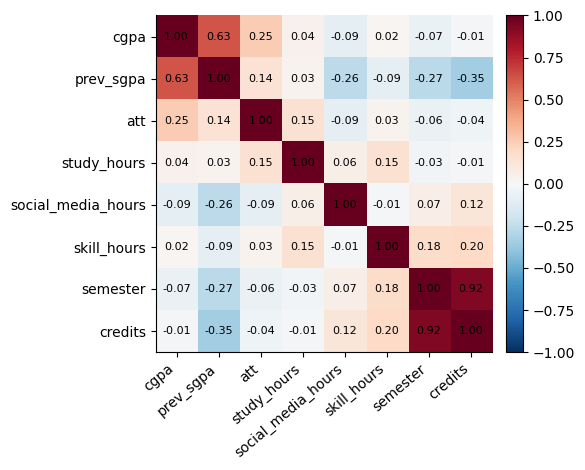

Tebak rata-rata                R2 = -0.003 | MAE = 0.392
Regresi linear, semua fitur    R2 =  0.447 | MAE = 0.268
Regresi linear, tanpa SGPA     R2 =  0.029 | MAE = 0.380
Regresi linear, SGPA saja      R2 =  0.434 | MAE = 0.270


In [15]:
num = ['cgpa', 'prev_sgpa', 'att', 'study_hours', 'social_media_hours', 'skill_hours', 'semester', 'credits']
corr = d[num].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6.2, 4.8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=40, ha='right')
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, fraction=0.046, pad=0.03); plt.tight_layout(); plt.savefig('fig/g4_korelasi.png', dpi=200); plt.show()

# baseline regresi, validasi silang 5-fold
fitur = ['prev_sgpa', 'att', 'study_hours', 'study_sessions', 'social_media_hours', 'skill_hours', 'semester']
dd = d.dropna(subset=fitur)
kf = KFold(5, shuffle=True, random_state=42)
for nama, model, cols_ in [('Tebak rata-rata', DummyRegressor(), fitur),
                           ('Regresi linear, semua fitur', LinearRegression(), fitur),
                           ('Regresi linear, tanpa SGPA', LinearRegression(), [f for f in fitur if f != 'prev_sgpa']),
                           ('Regresi linear, SGPA saja', LinearRegression(), ['prev_sgpa'])]:
    hasil = cross_validate(model, dd[cols_].values, dd.cgpa.values, cv=kf, scoring=('r2', 'neg_mean_absolute_error'))
    print(f"{nama:30s} R2 = {hasil['test_r2'].mean():6.3f} | MAE = {-hasil['test_neg_mean_absolute_error'].mean():.3f}")

**Catatan (Gambar 4):** SGPA sebelumnya paling kuat berhubungan dengan CGPA (Spearman 0,63). Ini wajar karena CGPA dihitung dari nilai semester sebelumnya. Dengan SGPA, regresi linear mencapai R² 0,45; tanpa SGPA hanya 0,03. Artinya kegiatan saja hampir tidak bisa memprediksi CGPA, dan SGPA harus diperlakukan hati-hati saat pemodelan agar tidak terjadi kebocoran data.

## 5.5 Representativitas sampel

In [16]:
print('Komposisi gender:'); print(d.gender.value_counts(normalize=True).round(3))
print('\nAngkatan 2019-2022:', round(d.admit_year.between(2019, 2022).mean() * 100), '% |',
      'angkatan < 2018 atau 2023:', int(((d.admit_year < 2018) | (d.admit_year == 2023)).sum()), 'mahasiswa')
print('Program studi:', d.program.unique().tolist())
print('Kehadiran 100% (data mentah):', int((mentah.att == 100).sum()), 'responden,',
      round((mentah.att == 100).mean() * 100), '%')

Komposisi gender:
gender
Male      0.566
Female    0.434
Name: proportion, dtype: float64

Angkatan 2019-2022: 93 % | angkatan < 2018 atau 2023: 31 mahasiswa
Program studi: ['BCSE']
Kehadiran 100% (data mentah): 357 responden, 30 %


**Catatan:** Semua responden dari satu program (BCSE) di satu kampus, survei sukarela, dan data dilaporkan sendiri (30% menjawab kehadiran 100%). Dataset layak dipakai untuk mencari pola awal, tetapi tidak untuk digeneralisasi ke semua mahasiswa.

---
# 6. Preprocessing

Menyiapkan data agar siap dipakai model di tahap UAS. Prinsipnya: **semua langkah yang "belajar" dari data (pengisian nilai kosong dan penskalaan) hanya dilatih pada data latih**, lalu diterapkan ke data uji. Dengan begitu informasi data uji tidak bocor ke proses pelatihan.

Langkah:
1. Pilih fitur: enam fitur angka, dua fitur ya/tidak, dan SGPA sebelumnya.
2. Ubah ya/tidak menjadi 0/1.
3. Siapkan dua skenario: **dengan SGPA** dan **tanpa SGPA** (untuk menguji apakah kegiatan sendirian cukup).
4. Bagi data latih dan uji (80:20) **sebelum** imputasi dan penskalaan.
5. Isi nilai kosong dengan median dan skalakan fitur angka (hanya dilatih pada data latih).

In [17]:
bersih['cocurricular_bin'] = (bersih.cocurricular == 'Yes').astype(int)
bersih['consultancy_bin'] = (bersih.consultancy == 'Yes').astype(int)

fitur_angka = ['att', 'study_hours', 'study_sessions', 'social_media_hours', 'skill_hours', 'semester']
fitur_biner = ['cocurricular_bin', 'consultancy_bin']
X = bersih[['prev_sgpa'] + fitur_angka + fitur_biner]
y = bersih['cgpa']

# bagi dulu, baru olah
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)
print('Data latih:', X_latih.shape, '| data uji:', X_uji.shape)

def buat_pipeline(kolom_angka, kolom_biner):
    return ColumnTransformer([
        ('angka', Pipeline([('isi', SimpleImputer(strategy='median')), ('skala', StandardScaler())]), kolom_angka),
        ('biner', 'passthrough', kolom_biner),
    ])

skenario = {
    'dengan_sgpa': (['prev_sgpa'] + fitur_angka, fitur_biner),
    'tanpa_sgpa': (fitur_angka, fitur_biner),
}
hasil_pre = {}
for nama, (ang, bin_) in skenario.items():
    pre = buat_pipeline(ang, bin_).fit(X_latih[ang + bin_])
    hasil_pre[nama] = (pre.transform(X_latih[ang + bin_]), pre.transform(X_uji[ang + bin_]))
    a, b = hasil_pre[nama]
    print(f'{nama:12s} latih {a.shape}, uji {b.shape} | rata-rata fitur angka (latih): {a[:, :len(ang)].mean():.3f}')
print('Nilai kosong tersisa setelah imputasi:', int(np.isnan(hasil_pre['dengan_sgpa'][0]).sum()))

Data latih: (924, 9) | data uji: (231, 9)
dengan_sgpa  latih (924, 9), uji (231, 9) | rata-rata fitur angka (latih): 0.000
tanpa_sgpa   latih (924, 8), uji (231, 8) | rata-rata fitur angka (latih): 0.000
Nilai kosong tersisa setelah imputasi: 0


In [18]:
# simpan data bersih agar notebook UAS bisa melanjutkan
bersih.to_csv('data/data_bersih.csv', index=False)
print('Tersimpan: data/data_bersih.csv,', bersih.shape)

Tersimpan: data/data_bersih.csv, (1155, 34)


**Catatan.** Setelah preprocessing, data latih dan uji sudah berskala dan tanpa nilai kosong, dalam dua skenario fitur. Pembagian memakai `random_state=42` agar hasilnya sama setiap dijalankan.